# Machine Learning Midterm

Breast Cancer Wisconsin

I compare unscaled and scaled features using three training/validation splits. I select a classifier using validation macro-F1 and use the fixed test set for the final check. K-Means is a separate comparison based on cluster assignments.

## Notebook setup

In [1]:
import json
import os
import platform
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.cluster import KMeans
from sklearn.datasets import load_breast_cancer, load_wine
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, adjusted_rand_score, auc, classification_report,
    ConfusionMatrixDisplay, confusion_matrix, f1_score, precision_recall_fscore_support,
    roc_auc_score, roc_curve, silhouette_score,
)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from threadpoolctl import threadpool_limits

SEEDS = [42, 52, 62]
FINAL_SEED = 42
REPRESENTATIONS = ["unscaled", "scaled"]
FIGURES = Path("figures")


def show_figure(fig, dataset, name):
    FIGURES.mkdir(exist_ok=True)
    path = FIGURES / f"{dataset}_{name}.png"
    fig.savefig(path, dpi=170, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    display(Image(filename=str(path), width=850))


def classifier_metrics(y, pred, probabilities, classes, dataset):
    # Check denominators before asking sklearn to replace undefined scores.
    undefined_precision = [int(label) for label in classes if not (pred == label).any()]
    undefined_recall = [int(label) for label in classes if not (y == label).any()]
    precision, recall, f1, _ = precision_recall_fscore_support(
        y, pred, labels=classes, average="macro", zero_division=0
    )
    if dataset == "breast_cancer":
        malignant = list(classes).index(0)
        auc = roc_auc_score((y == 0).astype(int), probabilities[:, malignant])
    else:
        auc = roc_auc_score(y, probabilities, labels=classes, multi_class="ovr", average="macro")
    scores = dict(accuracy=accuracy_score(y, pred), macro_precision=precision,
                  macro_recall=recall, macro_f1=f1, roc_auc=auc)
    return scores, undefined_precision, undefined_recall


def cluster_metrics(X, y, clusters):
    occupied = len(np.unique(clusters))
    silhouette = np.nan
    if 2 <= occupied < len(X):
        silhouette = silhouette_score(X, clusters)
    return dict(ari=adjusted_rand_score(y, clusters), silhouette=silhouette)


def summarize(runs, keys, metrics):
    # Pandas groupby std uses sample standard deviation (ddof=1).
    summary = runs.groupby(keys, sort=False, dropna=False)[metrics].agg(["mean", "std"])
    summary.columns = [f"{metric}_{stat}" for metric, stat in summary.columns]
    return summary.reset_index()


def parameter_figure(summary, algorithm, settings, title):
    fig, ax = plt.subplots(figsize=(8.4, 3.4), layout="constrained")
    for index, (rep, color) in enumerate(zip(REPRESENTATIONS, ["#285783", "#b34d19"])):
        rows = summary.query("algorithm == @algorithm and representation == @rep")
        rows = rows.set_index("parameter_value").loc[settings]
        for j, (split, line) in enumerate([("train", "--"), ("val", "-")]):
            key = f"{split}_macro_f1"
            x = np.arange(len(settings)) + (index * 2 + j - 1.5) * 0.055
            split_name = {"train": "Training", "val": "Validation"}[split]
            ax.errorbar(x, rows[f"{key}_mean"], yerr=rows[f"{key}_std"],
                        fmt=f"o{line}", capsize=3, color=color, label=f"{rep.title()} · {split_name}")
    ax.set(xticks=range(len(settings)), xticklabels=settings,
           xlabel="Maximum depth" if algorithm == "Decision Tree" else "Number of neighbours",
           ylabel="Macro-F1", title=title)
    ax.grid(axis="y", alpha=0.25)
    ax.legend(loc="lower left", ncol=2, fontsize=8)
    return fig

## 1. Loading the Datasets

In [2]:
dataset = "breast_cancer"
if dataset == "breast_cancer":
    dataset_name = "Breast Cancer Wisconsin"
    data = load_breast_cancer()
else:
    dataset_name = "Wine Classification"
    data = load_wine()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, index=X.index, name="target")
class_names = dict(enumerate(data.target_names.tolist()))
classes = np.array(list(class_names))
class_counts = y.value_counts().reindex(classes)

pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", None)
pd.set_option("display.precision", 4)
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

packages = ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "joblib", "threadpoolctl"]
print("Python", platform.python_version(), "|", ", ".join(f"{p} {version(p)}" for p in packages))
print(dataset_name, "| Feature shape:", X.shape)
display(X.head())
display(pd.DataFrame({"feature number": range(1, X.shape[1] + 1), "feature": X.columns}))
display(pd.DataFrame({"class name": pd.Series(class_names), "sample count": class_counts})
        .rename_axis("original target label"))
if dataset == "breast_cancer":
    print("Benign is the larger class. Malignant (0) is positive for binary evaluation.")
else:
    print("Class 1 is the largest class. I kept the three original labels.")

Python 3.12.14 | numpy 2.2.6, pandas 2.2.3, scipy 1.15.3, scikit-learn 1.7.2, matplotlib 3.10.7, joblib 1.5.2, threadpoolctl 3.6.0
Breast Cancer Wisconsin | Feature shape: (569, 30)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.1184,0.2776,0.3001,0.1471,0.2419,0.0787,1.0950,0.9053,8.589,153.40,0.0064,0.0490,0.0537,0.0159,0.0300,0.0062,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.1189
1,20.57,17.77,132.90,1326.0,0.0847,0.0786,0.0869,0.0702,0.1812,0.0567,0.5435,0.7339,3.398,74.08,0.0052,0.0131,0.0186,0.0134,0.0139,0.0035,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.0890
2,19.69,21.25,130.00,1203.0,0.1096,0.1599,0.1974,0.1279,0.2069,0.0600,0.7456,0.7869,4.585,94.03,0.0062,0.0401,0.0383,0.0206,0.0225,0.0046,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.0876
3,11.42,20.38,77.58,386.1,0.1425,0.2839,0.2414,0.1052,0.2597,0.0974,0.4956,1.1560,3.445,27.23,0.0091,0.0746,0.0566,0.0187,0.0596,0.0092,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.1730
4,20.29,14.34,135.10,1297.0,0.1003,0.1328,0.1980,0.1043,0.1809,0.0588,0.7572,0.7813,5.438,94.44,0.0115,0.0246,0.0569,0.0188,0.0176,0.0051,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.0768


,feature number,feature
0,1,mean radius
1,2,mean texture
2,3,mean perimeter
3,4,mean area
4,5,mean smoothness
5,6,mean compactness
6,7,mean concavity
7,8,mean concave points
8,9,mean symmetry
9,10,mean fractal dimension


,class name,sample count
original target label,,
0,malignant,212
1,benign,357


Benign is the larger class. Malignant (0) is positive for binary evaluation.


## 2. Dataset Quality Checks

In [3]:
missing = X.assign(target=y).isna().sum()
feature_duplicates = int(X.duplicated().sum())
full_duplicates = int(X.assign(target=y).duplicated().sum())
quality = pd.DataFrame({"missing": missing, "dtype": X.assign(target=y).dtypes.astype(str)})
q1 = X.quantile(0.25)
q3 = X.quantile(0.75)
iqr = q3 - q1
flags = ((X < q1 - 1.5 * iqr) | (X > q3 + 1.5 * iqr)).sum()
quality["IQR flags"] = flags.astype("Int64")
display(quality)
numeric = X.select_dtypes(include="number").shape[1]
print(f"Missing values: {missing.sum()}. Duplicate rows: {feature_duplicates} (features), "
      f"{full_duplicates} (features and label).")
print(f"Numerical features: {numeric}. Categorical features: {X.shape[1] - numeric}.")
print(f"{flags.idxmax()} has the most IQR flags ({flags.max()}). Extreme values can dominate "
      "Euclidean distances and pull K-Means centroids. They can also shift GaussianNB "
      "means and variances. I kept every row.")

,missing,dtype,IQR flags
mean radius,0,float64,14
mean texture,0,float64,7
mean perimeter,0,float64,13
mean area,0,float64,25
mean smoothness,0,float64,6
mean compactness,0,float64,16
mean concavity,0,float64,18
mean concave points,0,float64,10
mean symmetry,0,float64,15
mean fractal dimension,0,float64,15


Missing values: 0. Duplicate rows: 0 (features), 0 (features and label).
Numerical features: 30. Categorical features: 0.
area error has the most IQR flags (65). Extreme values can dominate Euclidean distances and pull K-Means centroids. They can also shift GaussianNB means and variances. I kept every row.


## 3. Exploratory Data Analysis (EDA)

,No.,Mean,Median,Min,Max,SD,Q1,Q3
mean radius,1,14.1273,13.3700,6.9810,28.1100,3.5240,11.7000,15.7800
mean texture,2,19.2896,18.8400,9.7100,39.2800,4.3010,16.1700,21.8000
mean perimeter,3,91.9690,86.2400,43.7900,188.5000,24.2990,75.1700,104.1000
mean area,4,654.8891,551.1000,143.5000,2501.0000,351.9141,420.3000,782.7000
mean smoothness,5,0.0964,0.0959,0.0526,0.1634,0.0141,0.0864,0.1053
mean compactness,6,0.1043,0.0926,0.0194,0.3454,0.0528,0.0649,0.1304
mean concavity,7,0.0888,0.0615,0.0000,0.4268,0.0797,0.0296,0.1307
mean concave points,8,0.0489,0.0335,0.0000,0.2012,0.0388,0.0203,0.0740
mean symmetry,9,0.1812,0.1792,0.1060,0.3040,0.0274,0.1619,0.1957
mean fractal dimension,10,0.0628,0.0615,0.0500,0.0974,0.0071,0.0577,0.0661


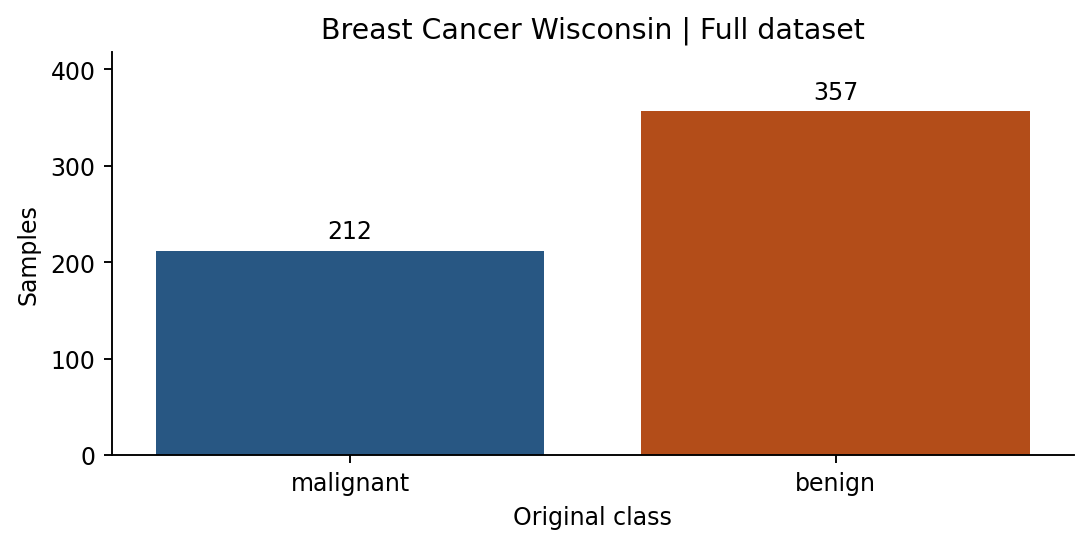

,Feature A,Feature B,Pearson r
1,mean radius,mean perimeter,0.9979
391,worst radius,worst perimeter,0.9937
2,mean radius,mean area,0.9874


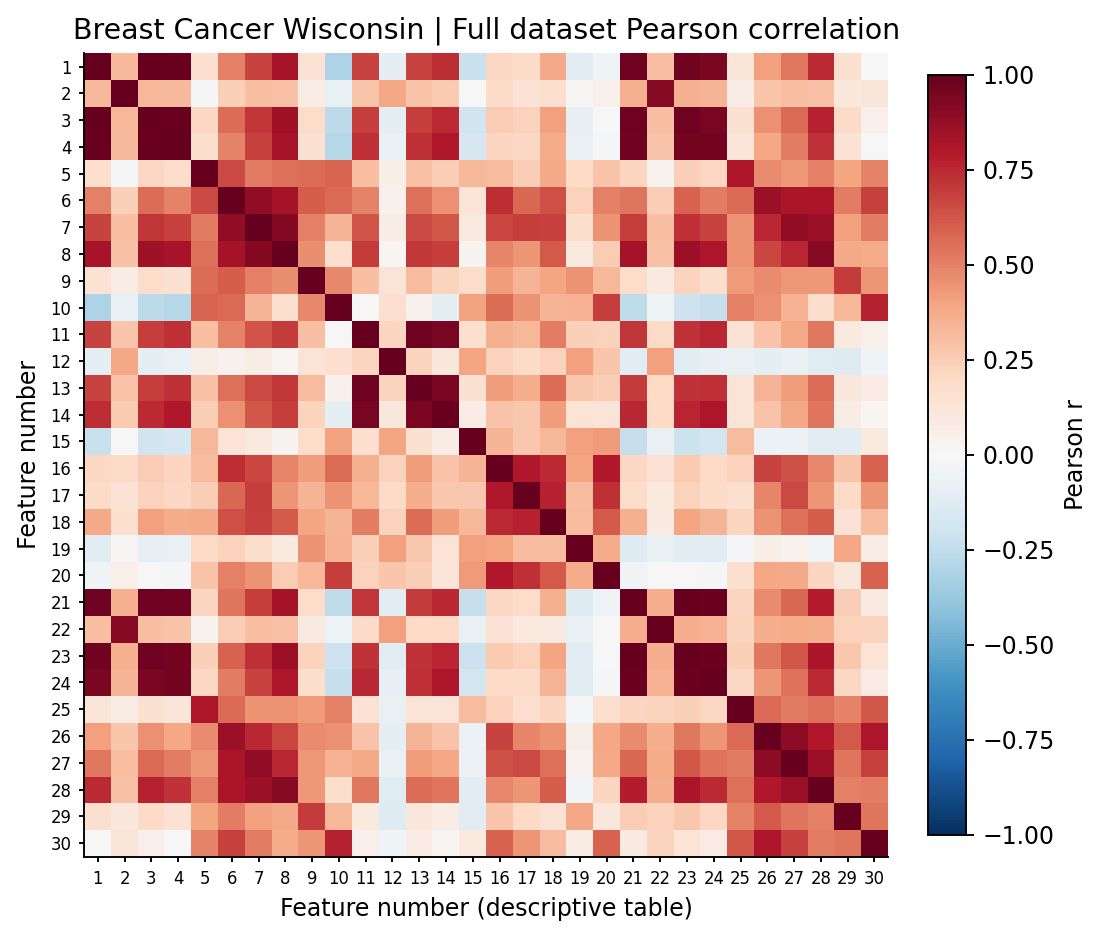

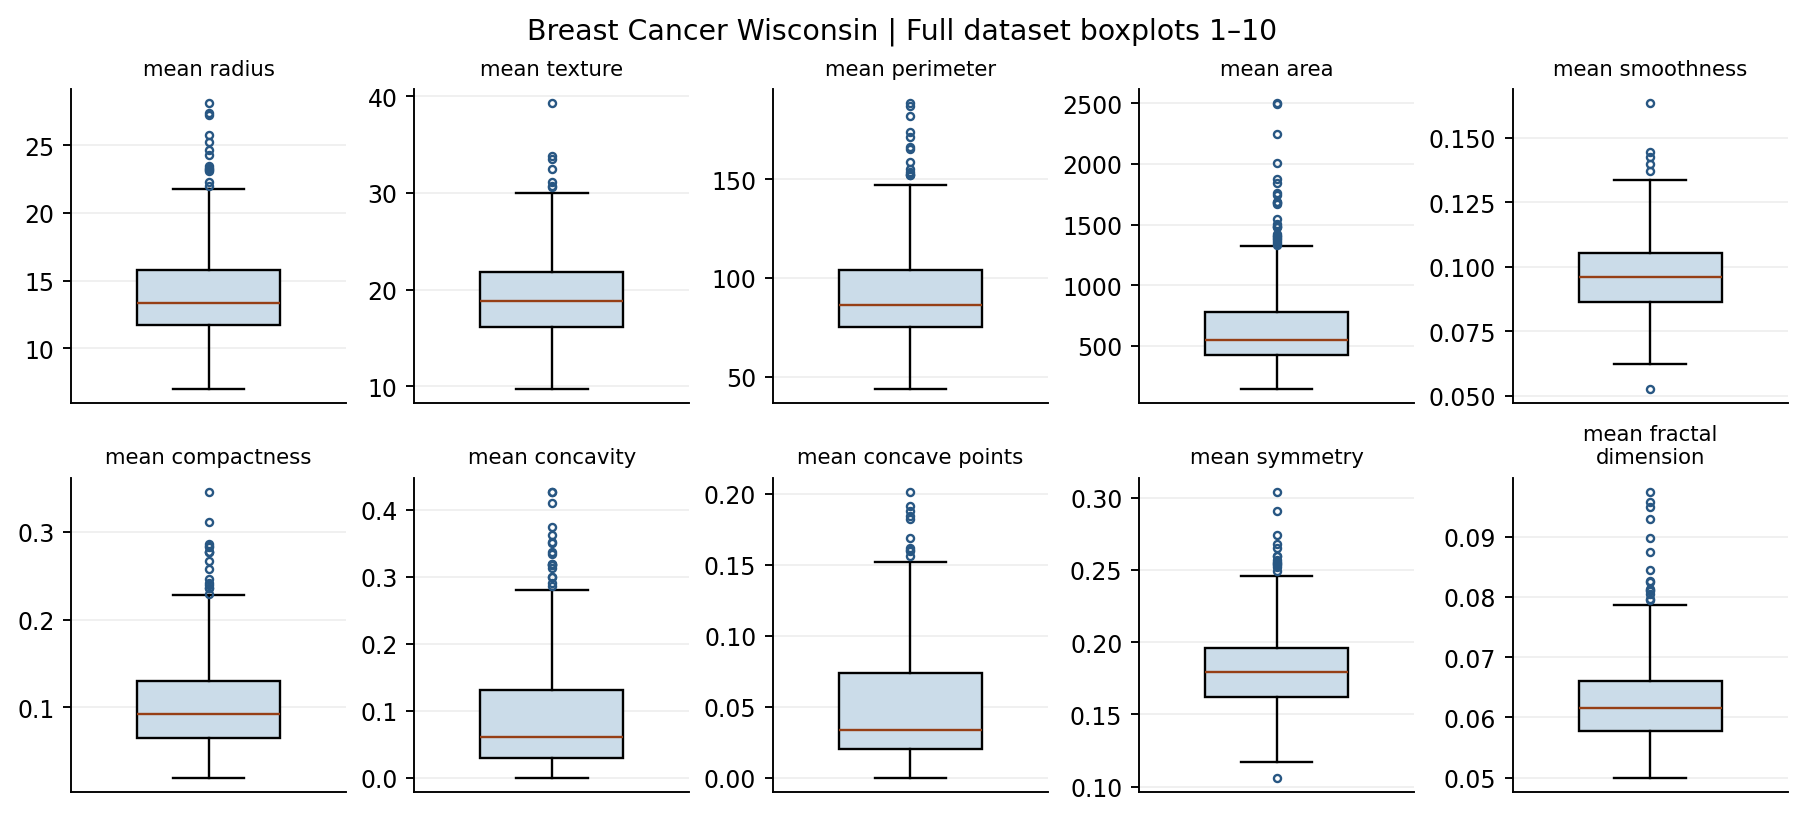

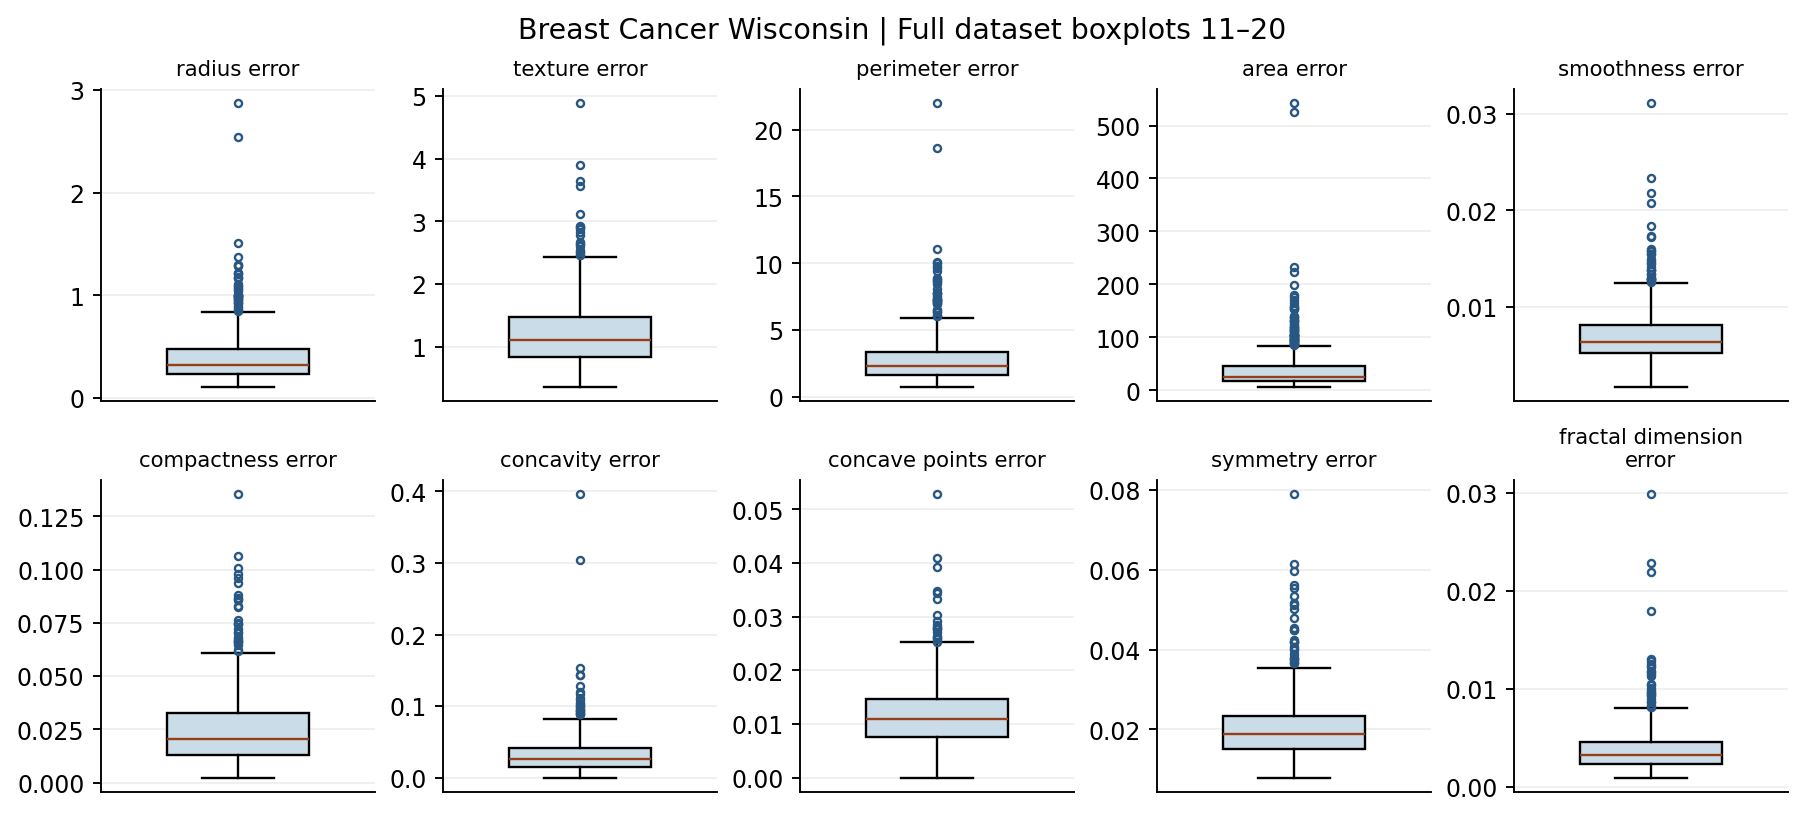

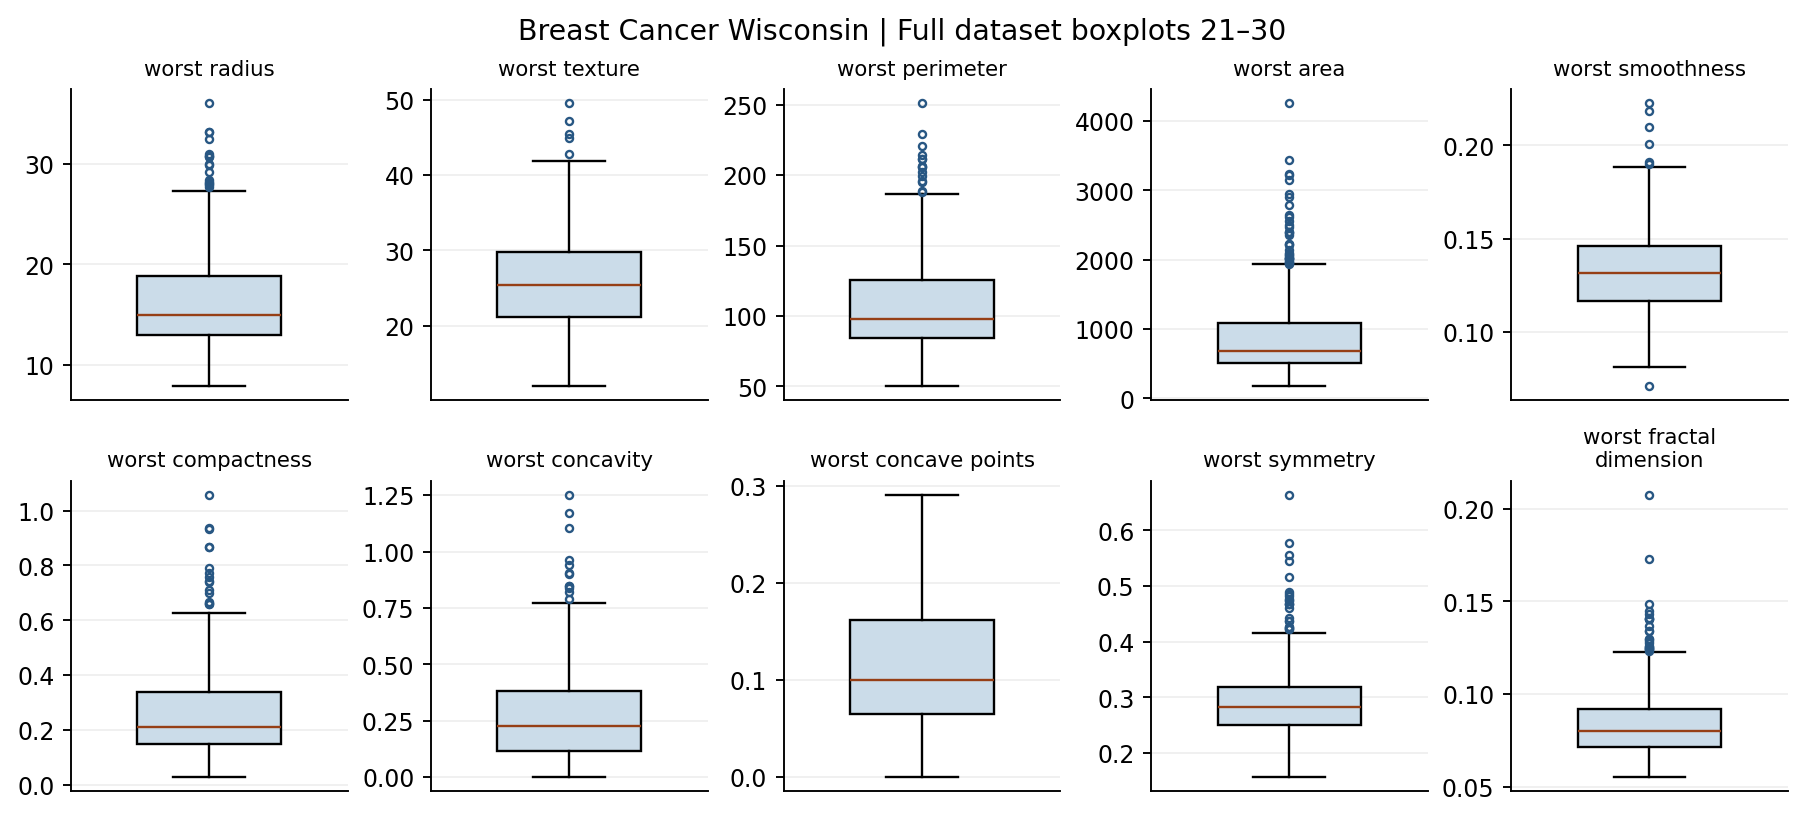

The strongest pairs are listed above once each. Related measurements carry similar information, but I kept all the original features.
Area varies over hundreds of units, while smoothness varies by fractions of a unit. Area error has a long upper tail with many points beyond the upper whisker.
The full-data checks describe the data. They do not determine any model inputs.


In [4]:
stats = pd.DataFrame({"Mean": X.mean(), "Median": X.median(), "Min": X.min(),
                      "Max": X.max(), "SD": X.std(), "Q1": q1, "Q3": q3})
stats.insert(0, "No.", range(1, X.shape[1] + 1))
display(stats)

fig, ax = plt.subplots(figsize=(6.3, 3.1), layout="constrained")
bars = ax.bar(list(class_names.values()), class_counts, color=["#285783", "#b34d19", "#528067"][:len(classes)])
ax.bar_label(bars, padding=3)
ax.set(title=f"{dataset_name} | Full dataset", ylabel="Samples",
       xlabel="Original class", ylim=(0, class_counts.max() * 1.17))
show_figure(fig, dataset, "classes")

corr = X.corr(method="pearson")
upper = np.triu(np.ones(corr.shape, dtype=bool), k=1)
pairs = corr.where(upper).stack().rename("Pearson r").reset_index()
pairs.columns = ["Feature A", "Feature B", "Pearson r"]
top_pairs = pairs.loc[pairs["Pearson r"].abs().nlargest(3).index]
display(top_pairs)

fig, ax = plt.subplots(figsize=(6.4, 5.7), layout="constrained")
heatmap = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
positions = range(X.shape[1])
numbers = range(1, X.shape[1] + 1)
ax.set(xticks=positions, yticks=positions, xticklabels=numbers, yticklabels=numbers,
       title=f"{dataset_name} | Full dataset Pearson correlation",
       xlabel="Feature number (descriptive table)", ylabel="Feature number")
ax.tick_params(labelsize=7, length=2)
fig.colorbar(heatmap, ax=ax, label="Pearson r", shrink=0.82)
show_figure(fig, dataset, "correlation")

from textwrap import fill

for start in range(0, X.shape[1], 10):
    features = X.columns[start:start + 10]
    fig, axes = plt.subplots(2, 5, figsize=(10.5, 4.7), layout="constrained")
    for ax, feature in zip(axes.flat, features):
        ax.boxplot(X[feature], widths=0.52, patch_artist=True,
                   boxprops={"facecolor": "#cbdce9"}, medianprops={"color": "#963f16"},
                   flierprops={"markersize": 3, "markeredgecolor": "#285783"})
        ax.set_title(fill(feature, 20), fontsize=9)
        ax.set_xticks([])
        ax.grid(axis="y", alpha=0.2)
    for ax in list(axes.flat)[len(features):]:
        ax.set_visible(False)
    fig.suptitle(f"{dataset_name} | Full dataset boxplots {start + 1}–{start + len(features)}")
    show_figure(fig, dataset, f"box_{start // 10 + 1}")

print("The strongest pairs are listed above once each. Related measurements carry similar "
      "information, but I kept all the original features.")
if dataset == "breast_cancer":
    print("Area varies over hundreds of units, while smoothness varies by fractions of a unit. "
          "Area error has a long upper tail with many points beyond the upper whisker.")
else:
    print("Proline spans hundreds of units, while hue spans roughly one unit. "
          "Malic acid has a longer upper tail and several points above its upper whisker.")
print("The full-data checks describe the data. They do not determine any model inputs.")

## 4. Splitting the Datasets

In [5]:
pool_idx, test_idx = train_test_split(X.index, test_size=0.20, stratify=y, random_state=42)
X_test, y_test = X.loc[test_idx], y.loc[test_idx]
splits, row_indices, split_rows = {}, {}, []
for seed in SEEDS:
    train_idx, val_idx = train_test_split(
        pool_idx, test_size=0.125, stratify=y.loc[pool_idx], random_state=seed
    )
    splits[seed] = (X.loc[train_idx], X.loc[val_idx], y.loc[train_idx], y.loc[val_idx])
    row_indices[seed] = {"train": train_idx.tolist(), "validation": val_idx.tolist(),
                         "test": X_test.index.tolist()}
    sets = [set(indices) for indices in row_indices[seed].values()]
    assert sum(map(len, sets)) == len(set.union(*sets)) == len(X)
    assert set.union(*sets) == set(X.index)
    for subset, indices in row_indices[seed].items():
        counts = y.loc[indices].value_counts().reindex(classes, fill_value=0)
        split_rows.append({"seed": seed, "subset": subset, "n": len(indices),
                           "percent": 100 * len(indices) / len(X),
                           **{class_names[i]: int(counts[i]) for i in classes}})
assert all(row_indices[s]["test"] == row_indices[FINAL_SEED]["test"] for s in SEEDS)
assert len({frozenset(row_indices[s]["validation"]) for s in SEEDS}) == len(SEEDS)
split_summary = pd.DataFrame(split_rows)
display(split_summary)

# A full, inspectable list with one column per subset. The test indices occur once.
index_table = {"fixed test": pd.Series(test_idx, dtype="Int64")}
for seed in SEEDS:
    for subset in ("train", "validation"):
        index_table[f"{subset} {seed}"] = pd.Series(row_indices[seed][subset], dtype="Int64")
index_table = pd.DataFrame(index_table)
with pd.option_context("display.max_rows", len(index_table)):
    display(index_table)
print("Each repetition covers the entire dataset without overlap. The same test rows "
      "are reserved once. Seed 42 is fixed in advance for final testing.")

,seed,subset,n,percent,malignant,benign
0,42,train,398,69.9473,149,249
1,42,validation,57,10.0176,21,36
2,42,test,114,20.0351,42,72
3,52,train,398,69.9473,149,249
4,52,validation,57,10.0176,21,36
5,52,test,114,20.0351,42,72
6,62,train,398,69.9473,149,249
7,62,validation,57,10.0176,21,36
8,62,test,114,20.0351,42,72


,fixed test,train 42,validation 42,train 52,validation 52,train 62,validation 62
0,256,301,454,427,142,3,61
1,428,390,49,81,243,508,299
2,501,420,50,294,135,471,410
3,363,356,197,47,274,379,33
4,564,446,393,12,263,319,134
5,464,56,96,46,181,56,119
6,358,82,333,249,254,342,36
7,343,221,557,348,510,279,220
8,516,339,60,312,187,476,350
9,567,364,151,245,438,451,487


Each repetition covers the entire dataset without overlap. The same test rows are reserved once. Seed 42 is fixed in advance for final testing.


## 5. Data Preprocessing and Scaling

In [6]:
preprocessing = {}
X_train_scaled, X_val_scaled = {}, {}
unscaled = {}
for seed, (X_train, X_val, y_train, y_val) in splits.items():
    imputer = None
    train_ready, val_ready = X_train, X_val
    if X_train.isna().any().any() or X_val.isna().any().any():
        imputer = SimpleImputer(strategy="median").set_output(transform="pandas")
        imputer.fit(X_train)
        train_ready, val_ready = imputer.transform(X_train), imputer.transform(X_val)
    scaler = StandardScaler().set_output(transform="pandas")
    scaler.fit(train_ready)
    preprocessing[seed] = (imputer, scaler)
    unscaled[seed] = (train_ready, val_ready)
    X_train_scaled[seed] = scaler.transform(train_ready)
    X_val_scaled[seed] = scaler.transform(val_ready)

imputer_42, scaler_42 = preprocessing[FINAL_SEED]
assert (imputer_42 is not None) or not X_test.isna().any().any()
X_test_unscaled = X_test if imputer_42 is None else imputer_42.transform(X_test)
X_test_scaled = scaler_42.transform(X_test_unscaled)
print("Seed 42 training rows before scaling")
display(splits[FINAL_SEED][0].head())
print("The same rows after scaling")
display(X_train_scaled[FINAL_SEED].head())
print("There were no missing values, so no imputer was fitted. StandardScaler subtracts "
      "the training mean and divides by the training standard deviation of each feature. "
      "Scaled values express distance from the training mean in standard deviations.")

Seed 42 training rows before scaling


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
301,12.46,19.89,80.43,471.3,0.0845,0.1014,0.0683,0.0310,0.1781,0.0625,0.3642,1.0400,2.579,28.32,0.0065,0.0337,0.0471,0.0140,0.0274,0.0047,13.46,23.07,88.13,551.3,0.1050,0.2158,0.1904,0.0762,0.2685,0.0776
390,10.26,12.22,65.75,321.6,0.1000,0.0754,0.0192,0.0197,0.1800,0.0657,0.1911,0.5477,1.348,11.88,0.0057,0.0137,0.0085,0.0069,0.0194,0.0024,11.38,15.65,73.23,394.5,0.1343,0.1650,0.0862,0.0670,0.2937,0.0772
420,11.57,19.04,74.20,409.7,0.0855,0.0772,0.0549,0.0143,0.2031,0.0627,0.2864,1.4400,2.206,20.30,0.0073,0.0205,0.0445,0.0088,0.0187,0.0033,13.07,26.98,86.43,520.5,0.1249,0.1937,0.2560,0.0666,0.3035,0.0828
356,13.05,18.59,85.09,512.0,0.1082,0.1304,0.0960,0.0560,0.2035,0.0650,0.3106,1.5100,2.590,21.57,0.0078,0.0393,0.0511,0.0188,0.0286,0.0057,14.19,24.85,94.22,591.2,0.1343,0.2658,0.2573,0.1258,0.3113,0.0832
446,17.75,28.03,117.30,981.6,0.1000,0.1314,0.1698,0.0829,0.1713,0.0592,0.3897,1.0770,2.873,43.95,0.0047,0.0202,0.0370,0.0111,0.0124,0.0026,21.53,38.54,145.40,1437.0,0.1401,0.3762,0.6399,0.1970,0.2972,0.0907


The same rows after scaling


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
301,-0.4648,0.1768,-0.4675,-0.5187,-0.8838,-0.0733,-0.2806,-0.4667,-0.0768,-0.0693,-0.1311,-0.2897,-0.1268,-0.2652,-0.1787,0.4117,0.4137,0.3498,0.7268,0.2939,-0.5734,-0.3791,-0.5611,-0.5783,-1.2264,-0.2594,-0.4165,-0.5849,-0.3396,-0.3582
390,-1.0841,-1.5530,-1.0653,-0.9445,0.2505,-0.5540,-0.8688,-0.7525,-0.0096,0.3752,-0.7658,-1.1679,-0.7372,-0.6437,-0.4444,-0.6585,-0.7412,-0.7657,-0.1679,-0.5237,-1.0011,-1.5474,-1.0004,-0.8549,0.0699,-0.5730,-0.8928,-0.7236,0.0461,-0.3811
420,-0.7154,-0.0149,-0.7212,-0.6939,-0.8140,-0.5207,-0.4418,-0.8890,0.8065,-0.0443,-0.4164,0.4239,-0.3118,-0.4498,0.0557,-0.2943,0.3344,-0.4720,-0.2460,-0.1766,-0.6536,0.2366,-0.6112,-0.6326,-0.3460,-0.3959,-0.1167,-0.7284,0.1961,-0.0735
356,-0.2988,-0.1164,-0.2778,-0.4030,0.8555,0.4632,0.0517,0.1660,0.8206,0.2807,-0.3276,0.5488,-0.1214,-0.4206,0.2214,0.7123,0.5333,1.0928,0.8607,0.6755,-0.4233,-0.0988,-0.3815,-0.5079,0.0699,0.0492,-0.1108,0.1548,0.3155,-0.0555
446,1.0243,2.0126,1.0339,0.9325,0.2512,0.4817,0.9359,0.8458,-0.3170,-0.5319,-0.0375,-0.2237,0.0190,0.0947,-0.7476,-0.3114,0.1102,-0.1105,-0.9500,-0.4574,1.0861,2.0568,1.1275,0.9841,0.3265,0.7307,1.6376,1.2177,0.0997,0.3594


There were no missing values, so no imputer was fitted. StandardScaler subtracts the training mean and divides by the training standard deviation of each feature. Scaled values express distance from the training mean in standard deviations.


## 6. Preparing the Two Data Representations

In [7]:
representations = {}
for seed in SEEDS:
    representations[seed] = {"unscaled": unscaled[seed],
                             "scaled": (X_train_scaled[seed], X_val_scaled[seed])}
    for original, scaled in zip(*representations[seed].values()):
        assert original.index.equals(scaled.index)
        assert original.columns.equals(scaled.columns)
test_features = {"unscaled": X_test_unscaled, "scaled": X_test_scaled}
print("Both representations keep the same features and sample indices. This makes "
      "each scaled versus unscaled comparison use exactly the same split.")

Both representations keep the same features and sample indices. This makes each scaled versus unscaled comparison use exactly the same split.


## 7. Training the Classification Models

In [8]:
depths = [2, 3, 5, 10, None]
neighbours = [1, 3, 5, 7, 11]


def model_grid(seed):
    for depth in depths:
        yield "Decision Tree", "tree", "max_depth", str(depth), f"d{depth}", DecisionTreeClassifier(
            max_depth=depth, random_state=seed
        )
    for k in neighbours:
        yield "KNN", "knn", "n_neighbors", str(k), f"k{k}", KNeighborsClassifier(
            n_neighbors=k, weights="uniform", metric="euclidean"
        )
    yield "GaussianNB", "gnb", "defaults", "default", "default", GaussianNB()


records, classifier_42 = [], {}
with threadpool_limits(limits=1):
    for seed in SEEDS:
        _, _, y_train, y_val = splits[seed]
        for rep, (X_train, X_val) in representations[seed].items():
            for algorithm, short, param, value, code, model in model_grid(seed):
                config = f"{dataset}_{short}_{rep}_{code}"
                model.fit(X_train, y_train)
                assert np.array_equal(model.classes_, classes)
                train_pred = model.predict(X_train)
                val_scores, undef_p, undef_r = classifier_metrics(
                    y_val, model.predict(X_val), model.predict_proba(X_val), model.classes_, dataset
                )
                records.append({
                    "dataset": dataset, "run_id": f"{config}_s{seed}", "configuration_id": config,
                    "seed": seed, "algorithm": algorithm, "representation": rep,
                    "parameter": param, "parameter_value": value,
                    "train_accuracy": accuracy_score(y_train, train_pred),
                    "train_macro_f1": f1_score(y_train, train_pred, average="macro", zero_division=0),
                    **{f"val_{name}": score for name, score in val_scores.items()},
                    "undefined_val_precision_labels": json.dumps(undef_p),
                    "undefined_val_recall_labels": json.dumps(undef_r),
                })
                if seed == FINAL_SEED:
                    classifier_42[config] = model
classifier_runs = pd.DataFrame(records)
assert len(classifier_runs) == classifier_runs.run_id.nunique() == 66
print(f"{len(classifier_runs)} classifier fits. Each run trains on its own training rows. "
      "Only tree models use the seed as an estimator parameter. Training metrics show "
      "how well the models fit examples they have already seen.")

66 classifier fits. Each run trains on its own training rows. Only tree models use the seed as an estimator parameter. Training metrics show how well the models fit examples they have already seen.


## 8. Measuring Validation Performance

Validation scores by run


,dataset,run_id,configuration_id,seed,algorithm,representation,parameter,parameter_value,train_accuracy,train_macro_f1,val_accuracy,val_macro_precision,val_macro_recall,val_macro_f1,val_roc_auc,undefined_val_precision_labels,undefined_val_recall_labels
0,breast_cancer,breast_cancer_tree_unscaled_d2_s42,breast_cancer_tree_unscaled_d2,42,Decision Tree,unscaled,max_depth,2,0.9548,0.9516,0.8947,0.8947,0.8770,0.8845,0.8757,[],[]
1,breast_cancer,breast_cancer_tree_unscaled_d3_s42,breast_cancer_tree_unscaled_d3,42,Decision Tree,unscaled,max_depth,3,0.9724,0.9700,0.8947,0.8947,0.8770,0.8845,0.9193,[],[]
2,breast_cancer,breast_cancer_tree_unscaled_d5_s42,breast_cancer_tree_unscaled_d5,42,Decision Tree,unscaled,max_depth,5,0.9975,0.9973,0.9123,0.9095,0.9008,0.9048,0.9213,[],[]
3,breast_cancer,breast_cancer_tree_unscaled_d10_s42,breast_cancer_tree_unscaled_d10,42,Decision Tree,unscaled,max_depth,10,1.0000,1.0000,0.9298,0.9246,0.9246,0.9246,0.9246,[],[]
4,breast_cancer,breast_cancer_tree_unscaled_dNone_s42,breast_cancer_tree_unscaled_dNone,42,Decision Tree,unscaled,max_depth,None,1.0000,1.0000,0.9298,0.9246,0.9246,0.9246,0.9246,[],[]
5,breast_cancer,breast_cancer_knn_unscaled_k1_s42,breast_cancer_knn_unscaled_k1,42,KNN,unscaled,n_neighbors,1,1.0000,1.0000,0.8596,0.8553,0.8393,0.8459,0.8393,[],[]
6,breast_cancer,breast_cancer_knn_unscaled_k3_s42,breast_cancer_knn_unscaled_k3,42,KNN,unscaled,n_neighbors,3,0.9598,0.9567,0.8772,0.8803,0.8532,0.8636,0.9160,[],[]
7,breast_cancer,breast_cancer_knn_unscaled_k5_s42,breast_cancer_knn_unscaled_k5,42,KNN,unscaled,n_neighbors,5,0.9523,0.9487,0.8947,0.8947,0.8770,0.8845,0.9299,[],[]
8,breast_cancer,breast_cancer_knn_unscaled_k7_s42,breast_cancer_knn_unscaled_k7,42,KNN,unscaled,n_neighbors,7,0.9497,0.9459,0.9123,0.9095,0.9008,0.9048,0.9511,[],[]
9,breast_cancer,breast_cancer_knn_unscaled_k11_s42,breast_cancer_knn_unscaled_k11,42,KNN,unscaled,n_neighbors,11,0.9472,0.9431,0.9298,0.9342,0.9147,0.9230,0.9550,[],[]


Three-seed means and sample standard deviations, in selection order


,dataset,configuration_id,algorithm,representation,parameter,parameter_value,train_accuracy_mean,train_accuracy_std,train_macro_f1_mean,train_macro_f1_std,val_accuracy_mean,val_accuracy_std,val_macro_precision_mean,val_macro_precision_std,val_macro_recall_mean,val_macro_recall_std,val_macro_f1_mean,val_macro_f1_std,val_roc_auc_mean,val_roc_auc_std,selected
0,breast_cancer,breast_cancer_knn_scaled_k7,KNN,scaled,n_neighbors,7,0.9724,0.0025,0.9702,0.0028,0.9708,0.0268,0.9784,0.0197,0.9603,0.0364,0.9677,0.0297,0.9782,0.0194,True
1,breast_cancer,breast_cancer_knn_scaled_k11,KNN,scaled,n_neighbors,11,0.9715,0.0015,0.9694,0.0015,0.9649,0.0351,0.9746,0.0250,0.9524,0.0476,0.9608,0.0395,0.9945,0.0048,False
2,breast_cancer,breast_cancer_knn_scaled_k3,KNN,scaled,n_neighbors,3,0.9807,0.0038,0.9793,0.0041,0.9591,0.0203,0.9699,0.0144,0.9444,0.0275,0.9547,0.0228,0.9793,0.0162,False
3,breast_cancer,breast_cancer_knn_scaled_k5,KNN,scaled,n_neighbors,5,0.9740,0.0029,0.9721,0.0032,0.9591,0.0203,0.9699,0.0144,0.9444,0.0275,0.9547,0.0228,0.9795,0.0174,False
4,breast_cancer,breast_cancer_knn_scaled_k1,KNN,scaled,n_neighbors,1,1.0000,0.0000,1.0000,0.0000,0.9415,0.0203,0.9410,0.0283,0.9339,0.0160,0.9369,0.0213,0.9339,0.0160,False
5,breast_cancer,breast_cancer_gnb_unscaled_default,GaussianNB,unscaled,defaults,default,0.9372,0.0044,0.9323,0.0049,0.9415,0.0203,0.9384,0.0164,0.9372,0.0308,0.9369,0.0226,0.9797,0.0126,False
6,breast_cancer,breast_cancer_gnb_scaled_default,GaussianNB,scaled,defaults,default,0.9355,0.0052,0.9307,0.0058,0.9298,0.0175,0.9239,0.0140,0.9279,0.0289,0.9248,0.0201,0.9760,0.0149,False
7,breast_cancer,breast_cancer_tree_scaled_d10,Decision Tree,scaled,max_depth,10,1.0000,0.0000,1.0000,0.0000,0.9240,0.0101,0.9159,0.0112,0.9266,0.0170,0.9195,0.0112,0.9266,0.0170,False
8,breast_cancer,breast_cancer_tree_scaled_dNone,Decision Tree,scaled,max_depth,None,1.0000,0.0000,1.0000,0.0000,0.9240,0.0101,0.9159,0.0112,0.9266,0.0170,0.9195,0.0112,0.9266,0.0170,False
9,breast_cancer,breast_cancer_tree_unscaled_d10,Decision Tree,unscaled,max_depth,10,1.0000,0.0000,1.0000,0.0000,0.9240,0.0101,0.9159,0.0112,0.9266,0.0170,0.9195,0.0112,0.9266,0.0170,False


Frozen selection: breast_cancer_knn_scaled_k7
Runs with undefined validation precision: 0
Runs with undefined validation recall: 0


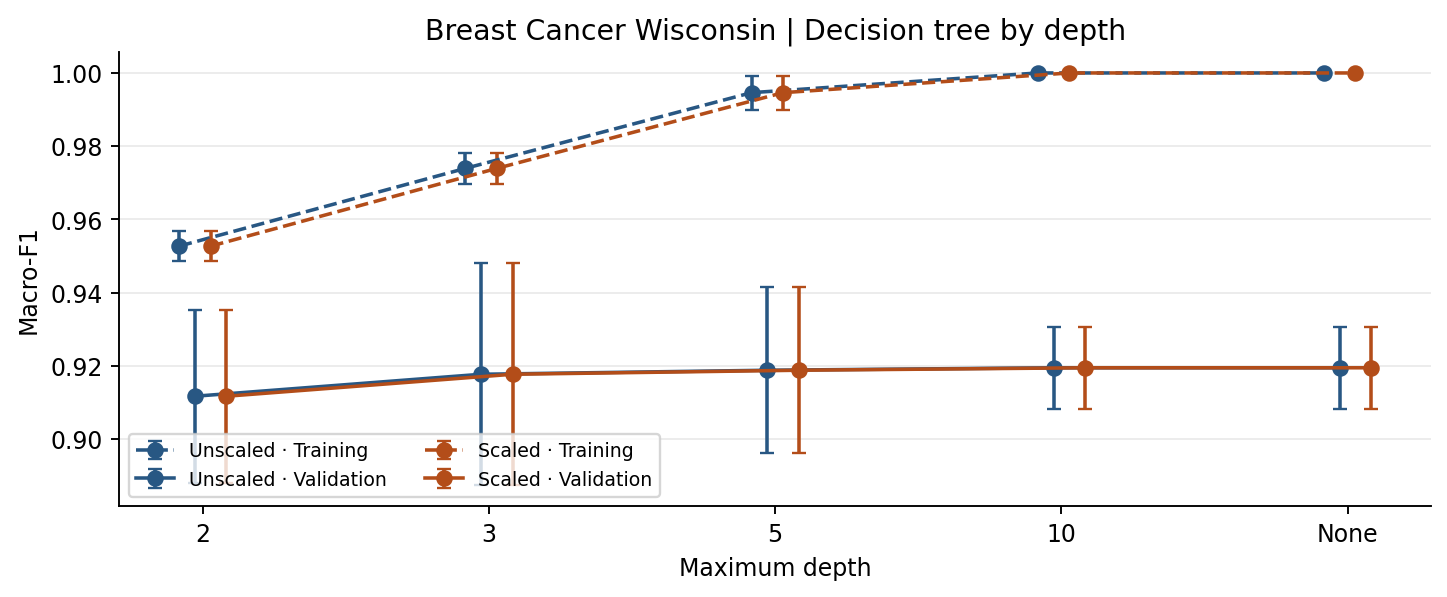

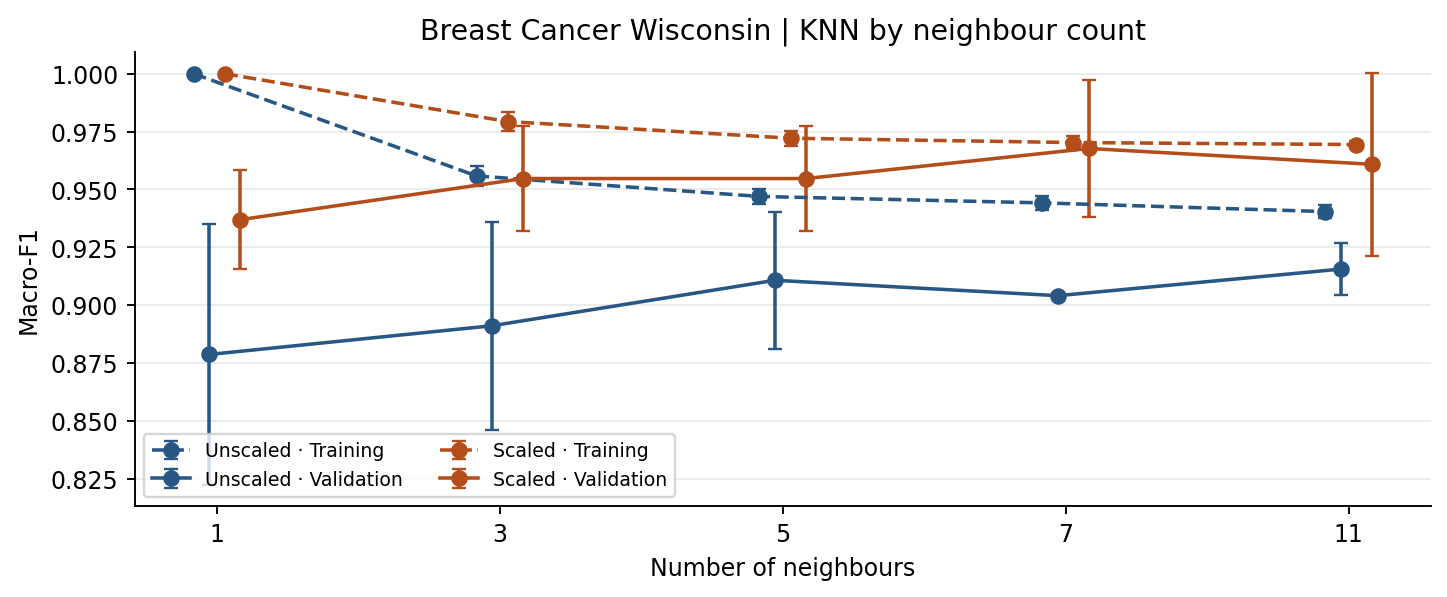

scaled minus unscaled
algorithm     parameter_value                       
Decision Tree 10                              0.0000
              2                               0.0000
              3                               0.0000
              5                               0.0000
              None                            0.0000
GaussianNB    default                        -0.0121
KNN           1                               0.0583
              11                              0.0453
              3                               0.0636
              5                               0.0440
              7                               0.0636

Decision Tree, unscaled: best setting 10 (0.9195), lowest 2 (0.9117).
Decision Tree, scaled: best setting 10 (0.9195), lowest 2 (0.9117).
KNN, unscaled: best setting 11 (0.9155), lowest 1 (0.8786).
KNN, scaled: best setting 7 (0.9677), lowest 1 (0.9369).
Largest mean training–validation F1 gap: breast_cancer_knn_unscaled_k1, 0.1214.
Validation F1 SD ranges from 0.0013 to 0.0566. Error bars describe the three splits.


In [9]:
score_columns = ["train_accuracy", "train_macro_f1", "val_accuracy", "val_macro_precision",
                 "val_macro_recall", "val_macro_f1", "val_roc_auc"]
config_columns = ["dataset", "configuration_id", "algorithm", "representation", "parameter", "parameter_value"]
assert classifier_runs.groupby("configuration_id").seed.nunique().eq(len(SEEDS)).all()
classifier_summary = summarize(classifier_runs, config_columns, score_columns)
classifier_summary = classifier_summary.sort_values(
    ["val_macro_f1_mean", "val_accuracy_mean", "val_macro_f1_std", "configuration_id"],
    ascending=[False, False, True, True],
).reset_index(drop=True)
assert len(classifier_summary) == 22
winner = classifier_summary.iloc[0]
classifier_summary["selected"] = classifier_summary.configuration_id.eq(winner.configuration_id)
print("Validation scores by run")
display(classifier_runs)
print("Three-seed means and sample standard deviations, in selection order")
display(classifier_summary)
print("Frozen selection:", winner.configuration_id)
print("Runs with undefined validation precision:",
      (classifier_runs.undefined_val_precision_labels != "[]").sum())
print("Runs with undefined validation recall:",
      (classifier_runs.undefined_val_recall_labels != "[]").sum())

show_figure(parameter_figure(classifier_summary, "Decision Tree", list(map(str, depths)),
                             f"{dataset_name} | Decision tree by depth"), dataset, "tree_depth")
show_figure(parameter_figure(classifier_summary, "KNN", list(map(str, neighbours)),
                             f"{dataset_name} | KNN by neighbour count"), dataset, "knn_neighbours")

comparison = classifier_summary.pivot(index=["algorithm", "parameter_value"],
                                      columns="representation", values="val_macro_f1_mean")
scaling_delta = (comparison.scaled - comparison.unscaled).rename("scaled minus unscaled")
display(scaling_delta.to_frame())
for algorithm in ["Decision Tree", "KNN"]:
    for rep in REPRESENTATIONS:
        rows = classifier_summary.query("algorithm == @algorithm and representation == @rep")
        best, worst = rows.iloc[0], rows.iloc[-1]
        print(f"{algorithm}, {rep}: best setting {best.parameter_value} "
              f"({best.val_macro_f1_mean:.4f}), lowest {worst.parameter_value} "
              f"({worst.val_macro_f1_mean:.4f}).")
largest_gap = classifier_summary.assign(
    gap=classifier_summary.train_macro_f1_mean - classifier_summary.val_macro_f1_mean
).sort_values("gap", ascending=False).iloc[0]
print(f"Largest mean training–validation F1 gap: {largest_gap.configuration_id}, {largest_gap.gap:.4f}.")
print(f"Validation F1 SD ranges from {classifier_summary.val_macro_f1_std.min():.4f} to "
      f"{classifier_summary.val_macro_f1_std.max():.4f}. Error bars describe the three splits.")

## 9. Evaluating the Selected Models on the Test Sets

,dataset,configuration_id,algorithm,representation,parameter_value,seed,val_macro_f1_mean,val_macro_f1_std,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,test_roc_auc,undefined_test_precision_labels,undefined_test_recall_labels
0,breast_cancer,breast_cancer_knn_scaled_k7,KNN,scaled,7,42,0.9677,0.0297,0.9737,0.98,0.9643,0.9713,0.9888,[],[]


,precision,recall,f1-score,support
malignant,1.00,0.9286,0.9630,42
benign,0.96,1.0000,0.9796,72


Undefined test precision classes: [] | Undefined test recall classes: []
Test minus mean validation macro-F1: +0.0036. The selected model stays fixed.


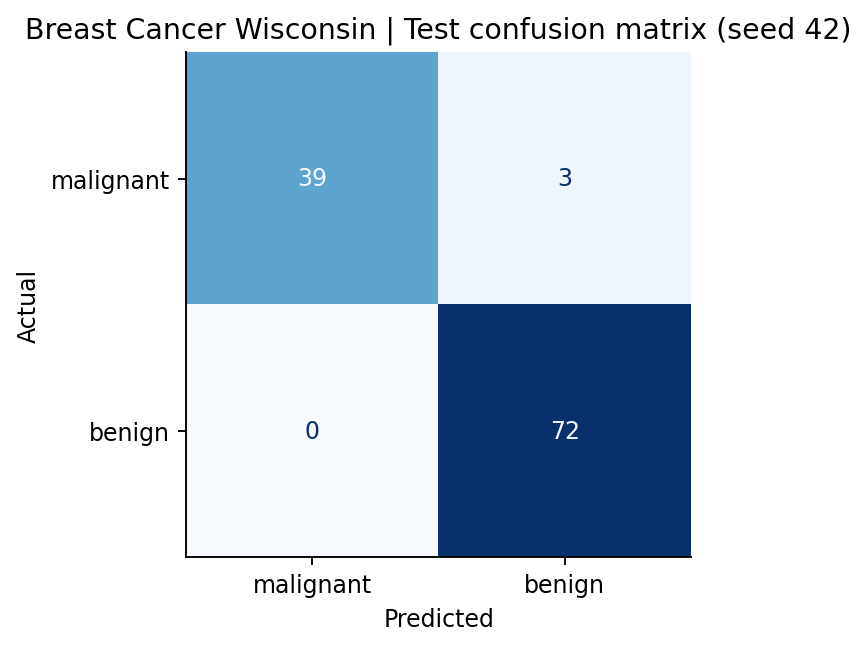

In [10]:
model = classifier_42[winner.configuration_id]
X_final = test_features[winner.representation]
pred = model.predict(X_final)
prob = model.predict_proba(X_final)
test_scores, undef_p, undef_r = classifier_metrics(y_test, pred, prob, model.classes_, dataset)
classifier_test = pd.DataFrame([{
    "dataset": dataset, "configuration_id": winner.configuration_id, "algorithm": winner.algorithm,
    "representation": winner.representation, "parameter_value": winner.parameter_value,
    "seed": FINAL_SEED, "val_macro_f1_mean": winner.val_macro_f1_mean,
    "val_macro_f1_std": winner.val_macro_f1_std,
    **{f"test_{name}": score for name, score in test_scores.items()},
    "undefined_test_precision_labels": json.dumps(undef_p),
    "undefined_test_recall_labels": json.dumps(undef_r),
}])
display(classifier_test)
report = classification_report(y_test, pred, labels=classes, target_names=list(class_names.values()),
                               output_dict=True, zero_division=0)
per_class = pd.DataFrame(report).T.loc[list(class_names.values())]
per_class["support"] = per_class["support"].astype(int)
display(per_class)
print("Undefined test precision classes:", undef_p, "| Undefined test recall classes:", undef_r)
delta = test_scores["macro_f1"] - winner.val_macro_f1_mean
print(f"Test minus mean validation macro-F1: {delta:+.4f}. The selected model stays fixed.")

cm = confusion_matrix(y_test, pred, labels=classes)
fig, ax = plt.subplots(figsize=(5.0, 3.7), layout="constrained")
ConfusionMatrixDisplay(cm, display_labels=list(class_names.values())).plot(
    ax=ax, cmap="Blues", colorbar=False, values_format="d"
)
ax.set(title=f"{dataset_name} | Test confusion matrix (seed 42)", xlabel="Predicted", ylabel="Actual")
show_figure(fig, dataset, "confusion")

In [11]:
label = 0
tp = int(cm[label, label])
fp = int(cm[:, label].sum() - tp)
fn = int(cm[label, :].sum() - tp)
tn = int(cm.sum() - tp - fp - fn)
manual = {}
for name, numerator, denominator in [
    ("precision", tp, tp + fp), ("recall", tp, tp + fn),
    ("f1-score", 2 * tp, 2 * tp + fp + fn),
]:
    value = numerator / denominator if denominator else None
    reported = report[class_names[label]][name]
    assert np.isclose(reported, value if value is not None else 0.0)
    manual[name] = {"numerator": numerator, "denominator": denominator,
                    "manual": value, "classification report": reported}
print(f"{class_names[label]} versus the rest | TP={tp}, FP={fp}, FN={fn}, TN={tn}")
display(pd.DataFrame(manual).T)
if dataset == "breast_cancer":
    print(f"Row order is malignant, benign. The top row is TP={tp}, FN={fn}. "
          f"The bottom row is FP={fp}, TN={tn}. An FN misses a malignant sample.")
else:
    off_diagonal = cm.copy()
    np.fill_diagonal(off_diagonal, 0)
    if off_diagonal.max():
        biggest = np.argwhere(off_diagonal == off_diagonal.max())
        for actual, guess in biggest:
            print(f"Largest off-diagonal: {class_names[actual]} → {class_names[guess]}, "
                  f"{off_diagonal[actual, guess]} test sample(s).")
    else:
        print("There are no test classification errors.")

malignant versus the rest | TP=39, FP=0, FN=3, TN=72


,numerator,denominator,manual,classification report
precision,39.0,39.0,1.0000,1.0000
recall,39.0,42.0,0.9286,0.9286
f1-score,78.0,81.0,0.9630,0.9630


Row order is malignant, benign. The top row is TP=39, FN=3. The bottom row is FP=0, TN=72. An FN misses a malignant sample.


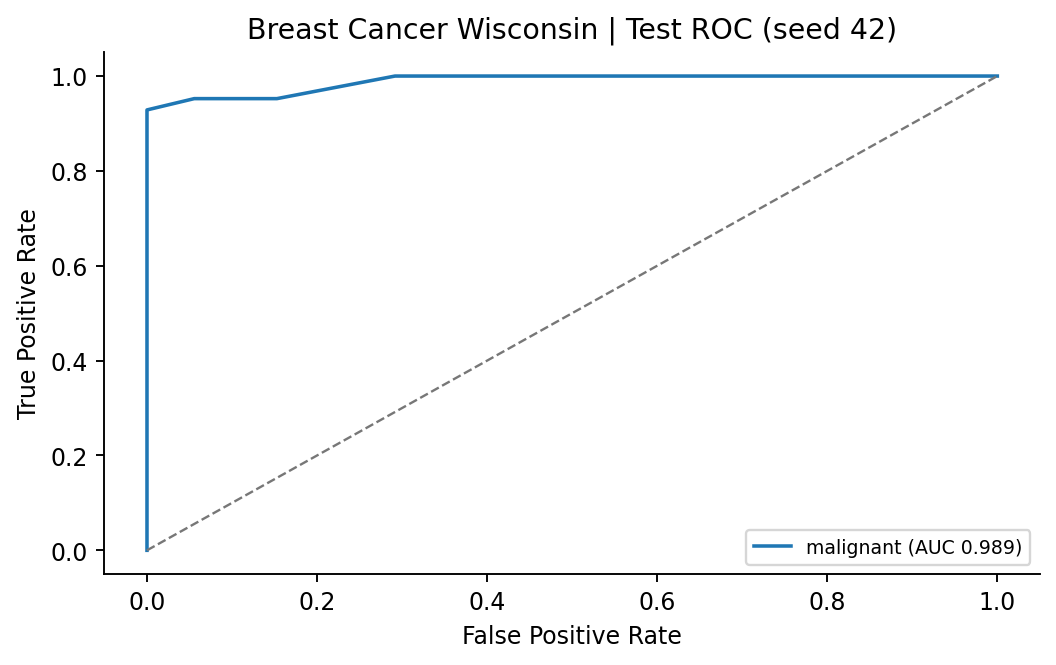

Test ROC-AUC: 0.9888. Raising a class's threshold usually reduces false positives and increases false negatives. I used the fitted model as it was and did not select a threshold on test data.


,actual,predicted
original row index,,
41,malignant,benign


This example is a missed malignant case.
The validation sets are small and the training sets overlap across seeds. The fixed test set was evaluated with one predeclared fitted seed.


In [12]:
fig, ax = plt.subplots(figsize=(6.1, 3.8), layout="constrained")
roc_aucs = {}
for roc_label in ([0] if dataset == "breast_cancer" else classes):
    column = list(model.classes_).index(roc_label)
    fpr, tpr, _ = roc_curve((y_test == roc_label).astype(int), prob[:, column])
    roc_aucs[class_names[roc_label]] = auc(fpr, tpr)
    ax.plot(fpr, tpr, label=f"{class_names[roc_label]} (AUC {auc(fpr, tpr):.3f})")
assert np.isclose(np.mean(list(roc_aucs.values())), test_scores["roc_auc"])
ax.plot([0, 1], [0, 1], "--", color="#777777", linewidth=1)
ax.set(xlabel="False Positive Rate", ylabel="True Positive Rate",
       title=f"{dataset_name} | Test ROC (seed 42)")
ax.legend(loc="lower right", fontsize=8)
show_figure(fig, dataset, "roc")
print(f"Test ROC-AUC: {test_scores['roc_auc']:.4f}. Raising a class's threshold usually "
      "reduces false positives and increases false negatives. I used the fitted model "
      "as it was and did not select a threshold on test data.")

errors = pd.DataFrame({"actual": y_test, "predicted": pred})
errors = errors.loc[errors.actual.ne(errors.predicted)]
if len(errors):
    example = errors.head(1)
    if dataset == "breast_cancer" and errors.actual.eq(0).any():
        example = errors.loc[errors.actual.eq(0)].head(1)
    display(example.replace(class_names).rename_axis("original row index"))
    if dataset == "breast_cancer":
        print("This example is a missed malignant case." if example.actual.iloc[0] == 0 else
              "This example is a benign sample incorrectly flagged as malignant.")
    else:
        print("The model assigned this sample to the wrong wine class.")
else:
    example = errors
    print("This test split has no errors. A single finite test set cannot establish "
          "that the classifier will be perfect on new samples.")
print("The validation sets are small and the training sets overlap across seeds. "
      "The fixed test set was evaluated with one predeclared fitted seed.")

## 10. K-Means Clustering

,dataset,run_id,seed,representation,n_clusters,n_init,train_inertia,val_ari,val_silhouette,occupied_val_clusters
0,breast_cancer,breast_cancer_kmeans_unscaled_s42,42,unscaled,2,10,5.1565e+07,0.3995,0.6387,2
1,breast_cancer,breast_cancer_kmeans_scaled_s42,42,scaled,2,10,7.9188e+03,0.4516,0.2854,2
2,breast_cancer,breast_cancer_kmeans_unscaled_s52,52,unscaled,2,10,4.9191e+07,0.6122,0.6975,2
3,breast_cancer,breast_cancer_kmeans_scaled_s52,52,scaled,2,10,8.0030e+03,0.5586,0.3750,2
4,breast_cancer,breast_cancer_kmeans_unscaled_s62,62,unscaled,2,10,5.3056e+07,0.5013,0.6958,2
5,breast_cancer,breast_cancer_kmeans_scaled_s62,62,scaled,2,10,7.9225e+03,0.7336,0.2758,2


,dataset,representation,train_inertia_mean,train_inertia_std,val_ari_mean,val_ari_std,val_silhouette_mean,val_silhouette_std,val_ari_valid_seeds,val_silhouette_valid_seeds
0,breast_cancer,unscaled,5.1271e+07,1.9496e+06,0.5043,0.1064,0.6773,0.0334,3,3
1,breast_cancer,scaled,7.9481e+03,4.7574e+01,0.5813,0.1424,0.3121,0.0547,3,3


Plot axes from seed-42 training: mean perimeter and fractal dimension error (|r| = 0.001).
Breast Cancer Wisconsin | Test contingency table | unscaled


cluster ID,0,1
actual class,,
malignant,14,28
benign,72,0


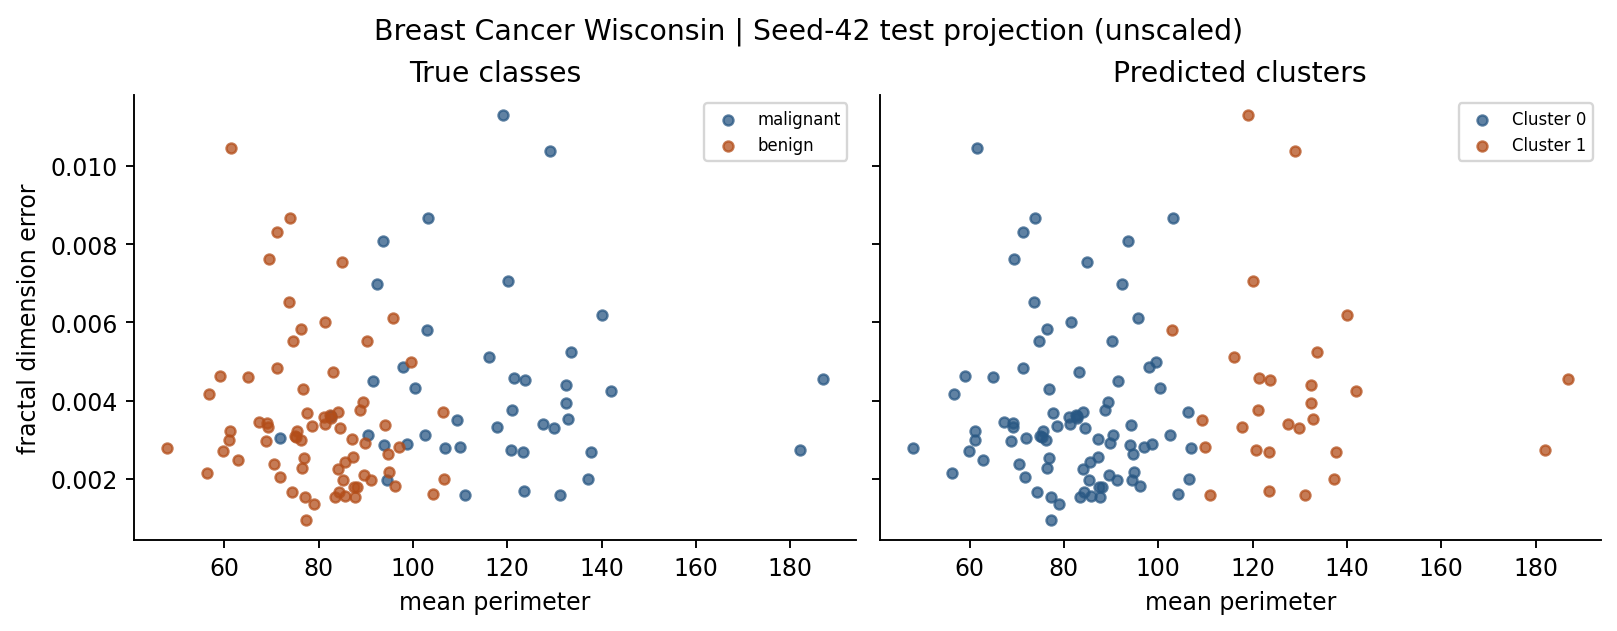

Breast Cancer Wisconsin | Test contingency table | scaled


cluster ID,0,1
actual class,,
malignant,5,37
benign,69,3


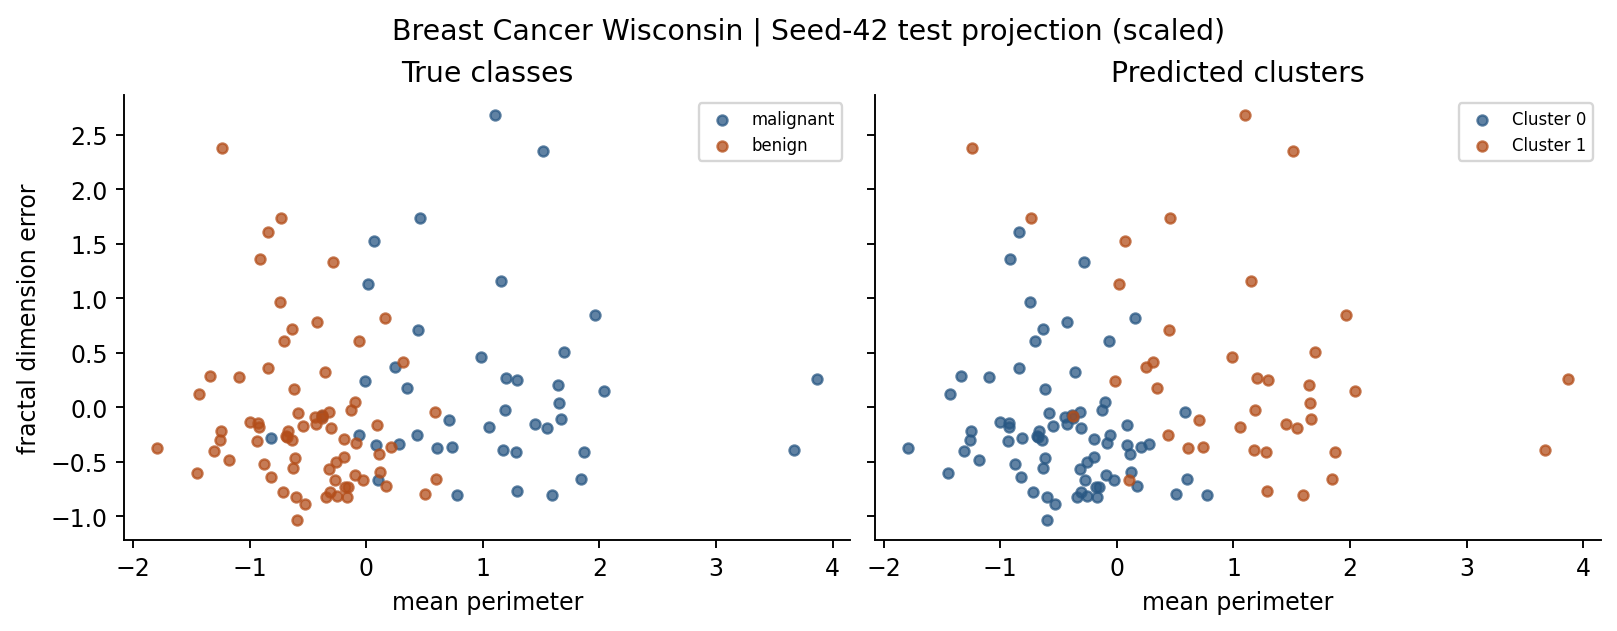

,dataset,representation,seed,n_clusters,n_init,test_cluster_counts,test_ari,test_silhouette
0,breast_cancer,unscaled,42,2,10,"{""0"": 86, ""1"": 28}",0.5585,0.7120
1,breast_cancer,scaled,42,2,10,"{""0"": 74, ""1"": 40}",0.7354,0.3251


Unscaled: 1 cluster(s) contain multiple true classes. Test ARI is 0.5585.
Scaled: 2 cluster(s) contain multiple true classes. Test ARI is 0.7354.
Scaling changes the distance geometry. Silhouette and inertia depend on that geometry, so their values across representations have different contexts. The projection shows two features. K-Means fitted all features without class labels, while the classifiers learned from features and labels.
Fit inventory: 66 classifier fits + 6 K-Means fits. The final evaluations reused seed-42 models.


In [13]:
kmeans_rows, kmeans_42 = [], {}
with threadpool_limits(limits=1):
    for seed, representations_at_seed in representations.items():
        _, _, _, y_val = splits[seed]
        for rep, (X_train, X_val) in representations_at_seed.items():
            kmeans = KMeans(n_clusters=len(classes), n_init=10, random_state=seed)
            kmeans.fit(X_train)
            val_clusters = kmeans.predict(X_val)
            scores = cluster_metrics(X_val, y_val, val_clusters)
            kmeans_rows.append({
                "dataset": dataset, "run_id": f"{dataset}_kmeans_{rep}_s{seed}",
                "seed": seed, "representation": rep, "n_clusters": len(classes), "n_init": 10,
                "train_inertia": kmeans.inertia_, "val_ari": scores["ari"],
                "val_silhouette": scores["silhouette"],
                "occupied_val_clusters": len(np.unique(val_clusters)),
            })
            if seed == FINAL_SEED:
                kmeans_42[rep] = kmeans
kmeans_runs = pd.DataFrame(kmeans_rows)
assert len(kmeans_runs) == kmeans_runs.run_id.nunique() == 6
kmeans_summary = summarize(kmeans_runs, ["dataset", "representation"],
                           ["train_inertia", "val_ari", "val_silhouette"])
valid_counts = kmeans_runs.groupby("representation")[["val_ari", "val_silhouette"]].count()
for score in valid_counts:
    kmeans_summary[f"{score}_valid_seeds"] = kmeans_summary.representation.map(valid_counts[score])
display(kmeans_runs.fillna("N/A"))
display(kmeans_summary.fillna("N/A"))
if kmeans_runs.val_silhouette.isna().any():
    print("N/A means fewer than two occupied clusters or as many clusters as samples. "
          "Undefined scores are excluded from the mean and SD.")

# Pick low-correlation axes from training only to show two less redundant directions.
# Both axes still use original features, and the models fit every feature.
training_corr = splits[FINAL_SEED][0].corr().abs()
training_pairs = training_corr.where(upper).stack()
feature_a, feature_b = training_pairs.idxmin()
print(f"Plot axes from seed-42 training: {feature_a} and {feature_b} "
      f"(|r| = {training_pairs.min():.3f}).")

cluster_tests, contingencies = [], {}
for rep in REPRESENTATIONS:
    X_cluster_test = test_features[rep]
    clusters = kmeans_42[rep].predict(X_cluster_test)
    scores = cluster_metrics(X_cluster_test, y_test, clusters)
    counts = np.bincount(clusters, minlength=len(classes))
    cluster_tests.append({
        "dataset": dataset, "representation": rep, "seed": FINAL_SEED,
        "n_clusters": len(classes), "n_init": 10,
        "test_cluster_counts": json.dumps({i: int(n) for i, n in enumerate(counts)}),
        "test_ari": scores["ari"], "test_silhouette": scores["silhouette"],
    })
    table = pd.crosstab(y_test, pd.Series(clusters, index=y_test.index)).reindex(
        index=classes, columns=classes, fill_value=0
    )
    table = table.rename(index=class_names).rename_axis(index="actual class", columns="cluster ID")
    contingencies[rep] = table
    print(f"{dataset_name} | Test contingency table | {rep}")
    display(table)
    if np.isnan(scores["silhouette"]):
        print("Test silhouette is N/A because the number of occupied clusters is outside [2, n − 1].")
    fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.6), sharex=True, sharey=True, layout="constrained")
    for ax, labels, names, title in [
        (axes[0], y_test, class_names, "True classes"),
        (axes[1], clusters, {int(i): f"Cluster {i}" for i in classes}, "Predicted clusters"),
    ]:
        for code, color in zip(classes, ["#285783", "#b34d19", "#528067"]):
            mask = np.asarray(labels) == code
            ax.scatter(X_cluster_test.loc[mask, feature_a], X_cluster_test.loc[mask, feature_b],
                       s=18, alpha=0.74, color=color, label=names[code])
        ax.set(title=title, xlabel=feature_a)
        ax.legend(fontsize=7)
    axes[0].set_ylabel(feature_b)
    fig.suptitle(f"{dataset_name} | Seed-42 test projection ({rep})")
    show_figure(fig, dataset, f"kmeans_{rep}")

kmeans_test = pd.DataFrame(cluster_tests)
display(kmeans_test.fillna("N/A"))
for rep, table in contingencies.items():
    mixed = int((table.gt(0).sum(axis=0) > 1).sum())
    print(f"{rep.title()}: {mixed} cluster(s) contain multiple true classes. "
          f"Test ARI is {kmeans_test.loc[kmeans_test.representation.eq(rep), 'test_ari'].iloc[0]:.4f}.")
print("Scaling changes the distance geometry. Silhouette and inertia depend on that "
      "geometry, so their values across representations have different contexts. "
      "The projection shows two features. K-Means fitted all features without class labels, "
      "while the classifiers learned from features and labels.")
print(f"Fit inventory: {len(classifier_runs)} classifier fits + {len(kmeans_runs)} K-Means fits. "
      "The final evaluations reused seed-42 models.")

# The paired runner uses this directory to combine notebook tables into six CSVs.
export_dir = os.environ.get("MIDTERM_EXPORT_DIR")
if export_dir:
    tables = {
        "classifier_runs": classifier_runs, "classifier_summary": classifier_summary,
        "classifier_test": classifier_test, "kmeans_runs": kmeans_runs,
        "kmeans_summary": kmeans_summary, "kmeans_test": kmeans_test,
    }
    for name, frame in tables.items():
        frame.to_csv(Path(export_dir) / f"{dataset}_{name}.csv", index=False)
    evidence = {
        "shape": list(X.shape), "class_names": class_names,
        "class_counts": class_counts.to_dict(), "split": split_rows,
        "missing": int(missing.sum()), "duplicates": full_duplicates, "flags": flags.to_dict(),
        "top_pairs": top_pairs.to_dict("records"), "stats": stats.reset_index().to_dict("records"),
        "confusion": cm.tolist(), "manual": manual, "per_class": per_class.to_dict("index"),
        "example": example.to_dict("index"), "errors": len(errors), "roc_aucs": roc_aucs,
        "axes": [feature_a, feature_b],
        "contingencies": {rep: table.to_dict("index") for rep, table in contingencies.items()},
    }
    (Path(export_dir) / f"{dataset}_evidence.json").write_text(
        json.dumps(evidence, indent=2), encoding="utf-8"
    )